# Evaluation: does the twin find what was planted?

Freshly generated synthetic users (4 plan personas, 30 varied people, 10 pure-noise users,
90 days each) are run through **the same code as production**: features, pattern discovery,
predictions and traits. They are then scored against the ground truth planted in the data.

Plan targets: pattern recall ≥ 80% in the top 5; 0–1 false insights on noise users; a
learning curve that beats the "7-day mean" baseline.

In [1]:
import sys
import warnings
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))
warnings.filterwarnings("ignore")
import matplotlib.pyplot as plt
import pandas as pd

from app.ml.evaluate import run

plt.rcParams.update(
    {
        "figure.dpi": 110,
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.edgecolor": "#c3c2b7",
        "axes.labelcolor": "#52514e",
        "xtick.color": "#898781",
        "ytick.color": "#898781",
        "font.size": 10,
    }
)
TWIN, BASE = "#2a78d6", "#d54810"  # validated pair (dataviz validator, white surface)

r = run(n_generated=30, n_noise=10)
p = r["patterns"]
print(f"Users: {r['users']['total']} ({r['users']['noise']} pure noise) | run time {r['seconds']}s")
print(f"Pattern recall@5: {p['recall_at_5']:.0%} of {p['planted_in_scope']} planted patterns")
print(
    f"False insights on noise users: max {p['false_insights_max']}, mean {p['false_insights_mean']}"
)
print(
    f"Task completion AUC: {r['tasks']['auc']}  |  chronotype accuracy: "
    f"{r['traits']['chronotype_accuracy']:.0%}  |  "
    f"optimism error: {r['traits']['optimism_abs_error']}"
)

Users: 44 (11 pure noise) | run time 124.5s
Pattern recall@5: 79% of 67 planted patterns
False insights on noise users: max 1, mean 0.09
Task completion AUC: 0.598  |  chronotype accuracy: 70%  |  optimism error: 0.015


## 1. Learning curve: twin vs the plan's baseline

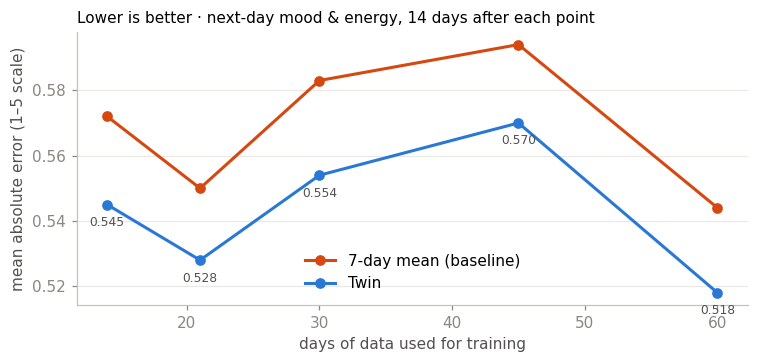

,twin_mae,baseline_mae,n,improvement
days of data,,,,
14,0.545,0.572,862.0,+4.7%
21,0.528,0.550,852.0,+4.0%
30,0.554,0.583,864.0,+5.0%
45,0.570,0.594,870.0,+4.0%
60,0.518,0.544,860.0,+4.8%


In [2]:
lc = pd.DataFrame(r["learning_curve"]).T
lc.index.name = "days of data"
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.plot(
    lc.index, lc["baseline_mae"], color=BASE, lw=2, marker="o", ms=6, label="7-day mean (baseline)"
)
ax.plot(lc.index, lc["twin_mae"], color=TWIN, lw=2, marker="o", ms=6, label="Twin")
for x, y in zip(lc.index, lc["twin_mae"], strict=False):
    ax.annotate(
        f"{y:.3f}",
        (x, y),
        textcoords="offset points",
        xytext=(0, -14),
        ha="center",
        fontsize=8,
        color="#52514e",
    )
ax.set_xlabel("days of data used for training")
ax.set_ylabel("mean absolute error (1–5 scale)")
ax.grid(axis="y", color="#ebe9e4")
ax.legend(frameon=False)
ax.set_title(
    "Lower is better · next-day mood & energy, 14 days after each point", loc="left", fontsize=10
)
plt.tight_layout()
plt.show()
lc.assign(improvement=lambda d: (1 - d.twin_mae / d.baseline_mae).map("{:+.1%}".format))

## 2. Pattern recall by planted pattern type

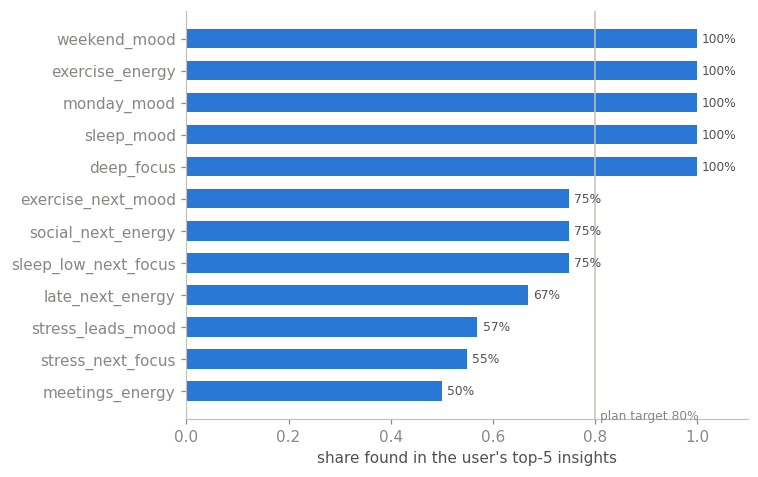

In [3]:
rec = pd.Series(p["recall_by_pattern"]).sort_values()
fig, ax = plt.subplots(figsize=(7, 0.32 * len(rec) + 0.6))
ax.barh(rec.index, rec.values, color=TWIN, height=0.6)
for i, v in enumerate(rec.values):
    ax.text(v + 0.01, i, f"{v:.0%}", va="center", fontsize=8, color="#52514e")
ax.axvline(0.8, color="#c3c2b7", lw=1)
ax.text(0.81, -0.9, "plan target 80%", fontsize=8, color="#898781")
ax.set_xlim(0, 1.1)
ax.set_xlabel("share found in the user's top-5 insights")
plt.tight_layout()
plt.show()

Patterns targeting **stress** are not mined as insights (the plan's insight targets are mood,
energy, focus and completion); they surface through the *stress triggers* trait instead.

## 3. Noise users: false insights

In [4]:
pd.Series(p["false_insights"], name="insights found").to_frame().T

,noise,noise01,noise02,noise03,noise04,noise05,noise06,noise07,noise08,noise09,noise10
insights found,0,0,1,0,0,0,0,0,0,0,0


**Reading this:** recall shows the method finds most planted links without being told where
to look. The noise users show it doesn't invent links (Benjamini–Hochberg keeps the
false-discovery rate low; the plan allows 0–1). The learning curve shows the twin beats the
naive baseline at every amount of data, by learning only when a pattern is reliable (models
must beat the user's 4-week norm in walk-forward validation, otherwise it falls back to it).